<a href="https://colab.research.google.com/github/Madhumitha-2007/datascience_interntask_bics/blob/main/customer_churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:

df.info()
print("\nMissing values:")
print(df.isnull().sum())



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [3]:

print("\nDuplicate rows:", df.duplicated().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())


Duplicate rows: 0

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [4]:
display(df.describe())

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


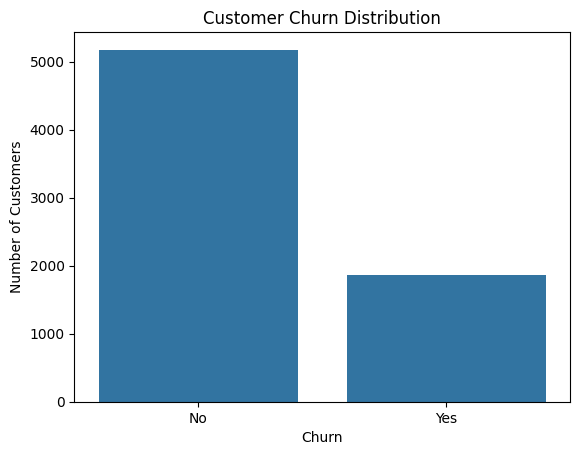

In [5]:
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()


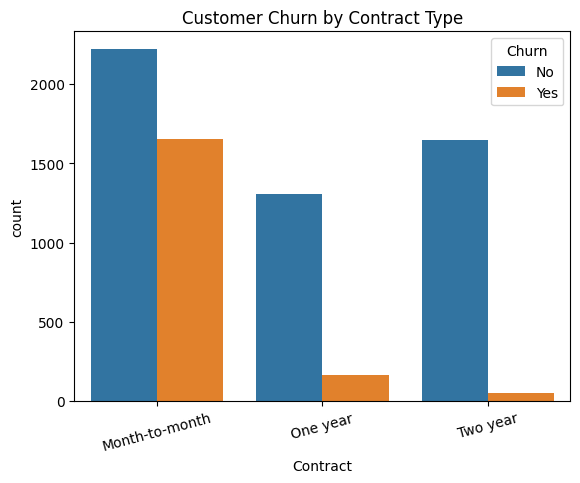

In [6]:
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Customer Churn by Contract Type")
plt.xticks(rotation=15)
plt.show()

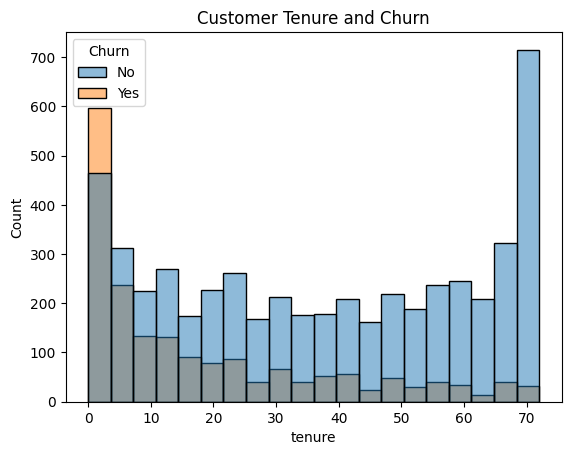

In [7]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=20)
plt.title("Customer Tenure and Churn")
plt.show()

In [9]:

data = df.copy()


data = data.drop_duplicates()


data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"], errors="coerce"
)

print("Dataset shape:", data.shape)
print("\nMissing values after conversion:")
print(data.isnull().sum()[data.isnull().sum() > 0])

Dataset shape: (7043, 21)

Missing values after conversion:
TotalCharges    11
dtype: int64


In [13]:

data = df.copy()


data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"], errors="coerce"
)

X = data.drop(columns=["customerID", "Churn"])
y = data["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 5634
Testing samples: 1409


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()


numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Numerical columns:", len(numeric_features))
print("Categorical columns:", len(categorical_features))
print("Preprocessing pipeline created successfully!")

Numerical columns: 4
Categorical columns: 15
Preprocessing pipeline created successfully!


In [16]:
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    )
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])


    pipeline.fit(X_train, y_train)


    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]


    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.738,0.504,0.783,0.614,0.841
1,Random Forest,0.783,0.618,0.476,0.538,0.822


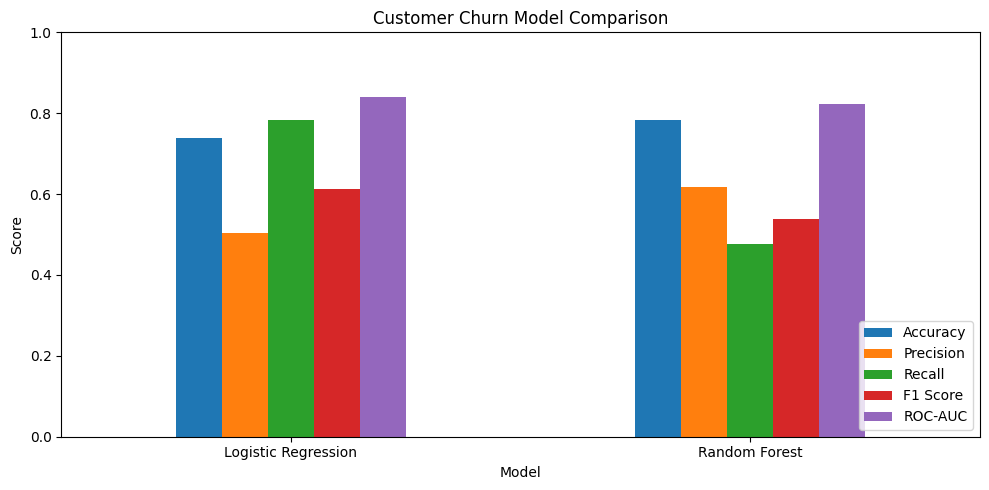

In [17]:
import matplotlib.pyplot as plt

results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Customer Churn Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Best Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

        Stay       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



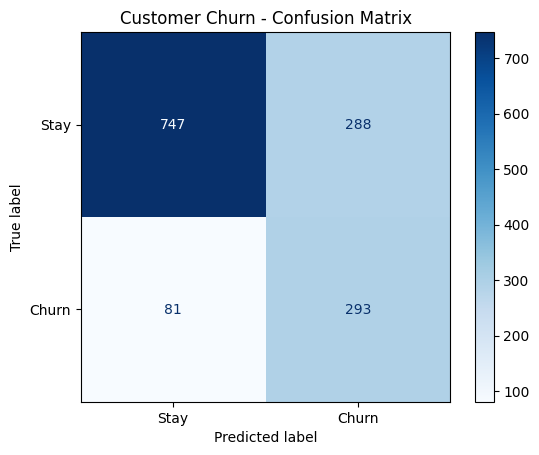

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

# Select the best model based on F1 Score
best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(), "Model"
]
best_model = trained_models[best_model_name]

# Generate predictions
y_pred = best_model.predict(X_test)

print("Best Model:", best_model_name)
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Stay", "Churn"]
))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stay", "Churn"]
)

display.plot(cmap="Blues")
plt.title("Customer Churn - Confusion Matrix")
plt.show()

                                  Feature  Importance
                              num__tenure    1.123589
                   cat__Contract_Two year    0.781257
         cat__InternetService_Fiber optic    0.705336
                      num__MonthlyCharges    0.663581
             cat__Contract_Month-to-month    0.663399
                 cat__InternetService_DSL    0.621009
                        num__TotalCharges    0.457211
                 cat__StreamingMovies_Yes    0.274978
cat__DeviceProtection_No internet service    0.274568
                  cat__InternetService_No    0.274568
  cat__OnlineSecurity_No internet service    0.274568
     cat__TechSupport_No internet service    0.274568
     cat__StreamingTV_No internet service    0.274568
    cat__OnlineBackup_No internet service    0.274568
 cat__StreamingMovies_No internet service    0.274568


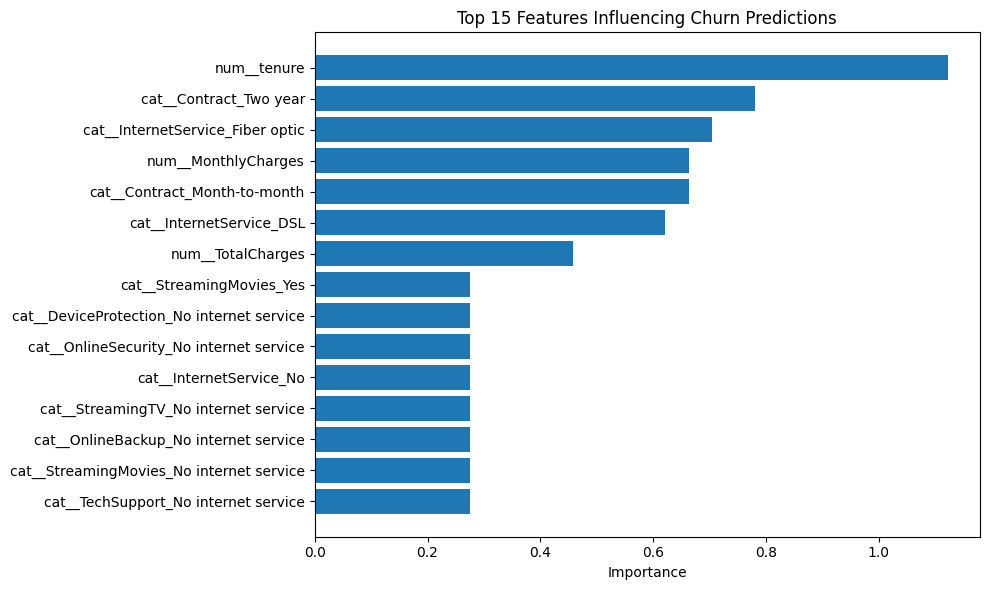

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get model importance
classifier = best_model.named_steps["model"]

if hasattr(classifier, "feature_importances_"):
    importance = classifier.feature_importances_
else:
    importance = abs(classifier.coef_[0])

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

print(feature_importance.head(15).to_string(index=False))

# Plot top 15 features
top_features = feature_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 15 Features Influencing Churn Predictions")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [24]:
import joblib

joblib.dump(best_model, "customer_churn_model.pkl")

print("Best model:", best_model_name)
print("Model saved successfully!")

Best model: Logistic Regression
Model saved successfully!


In [25]:
from google.colab import files

files.download("customer_churn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
from google.colab import files
uploaded = files.upload()

Saving customer_churn_model.pkl to customer_churn_model (1).pkl


In [27]:
import joblib

model = joblib.load("customer_churn_model.pkl")
print("Model loaded successfully!")

Model loaded successfully!


In [28]:
!pip install streamlit pyngrok

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 53.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 75.0 MB/s eta 0:00:00


In [29]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Customer Churn Prediction",
    page_icon="📊",
    layout="wide"
)

model = joblib.load("customer_churn_model.pkl")

st.title("📊 Customer Churn Prediction System")
st.write("Predict whether a telecom customer is likely to leave the service.")

st.sidebar.header("Customer Details")

gender = st.sidebar.selectbox("Gender", ["Male", "Female"])
senior = st.sidebar.selectbox("Senior Citizen", [0, 1])
partner = st.sidebar.selectbox("Has Partner?", ["Yes", "No"])
dependents = st.sidebar.selectbox("Has Dependents?", ["Yes", "No"])
tenure = st.sidebar.slider("Tenure (months)", 0, 72, 12)
phone = st.sidebar.selectbox("Phone Service", ["Yes", "No"])
multiple = st.sidebar.selectbox(
    "Multiple Lines", ["Yes", "No", "No phone service"]
)
internet = st.sidebar.selectbox(
    "Internet Service", ["DSL", "Fiber optic", "No"]
)
security = st.sidebar.selectbox(
    "Online Security", ["Yes", "No", "No internet service"]
)
backup = st.sidebar.selectbox(
    "Online Backup", ["Yes", "No", "No internet service"]
)
protection = st.sidebar.selectbox(
    "Device Protection", ["Yes", "No", "No internet service"]
)
support = st.sidebar.selectbox(
    "Tech Support", ["Yes", "No", "No internet service"]
)
tv = st.sidebar.selectbox(
    "Streaming TV", ["Yes", "No", "No internet service"]
)
movies = st.sidebar.selectbox(
    "Streaming Movies", ["Yes", "No", "No internet service"]
)
contract = st.sidebar.selectbox(
    "Contract", ["Month-to-month", "One year", "Two year"]
)
paperless = st.sidebar.selectbox("Paperless Billing", ["Yes", "No"])
payment = st.sidebar.selectbox(
    "Payment Method",
    [
        "Electronic check",
        "Mailed check",
        "Bank transfer (automatic)",
        "Credit card (automatic)"
    ]
)
monthly = st.sidebar.number_input(
    "Monthly Charges", min_value=0.0, value=70.0
)
total = st.sidebar.number_input(
    "Total Charges", min_value=0.0, value=840.0
)

if st.button("Predict Customer Churn"):
    customer = pd.DataFrame([{
        "gender": gender,
        "SeniorCitizen": senior,
        "Partner": partner,
        "Dependents": dependents,
        "tenure": tenure,
        "PhoneService": phone,
        "MultipleLines": multiple,
        "InternetService": internet,
        "OnlineSecurity": security,
        "OnlineBackup": backup,
        "DeviceProtection": protection,
        "TechSupport": support,
        "StreamingTV": tv,
        "StreamingMovies": movies,
        "Contract": contract,
        "PaperlessBilling": paperless,
        "PaymentMethod": payment,
        "MonthlyCharges": monthly,
        "TotalCharges": total
    }])

    prediction = model.predict(customer)[0]
    probability = model.predict_proba(customer)[0][1]

    st.subheader("Prediction Result")

    if prediction == 1:
        st.error("⚠️ The model predicts that this customer may churn.")
    else:
        st.success("✅ The model predicts that this customer may stay.")

    st.metric("Estimated Churn Probability", f"{probability:.1%}")
    st.progress(float(probability))

    st.caption(
        "This is a machine-learning estimate, not a guarantee "
        "of future customer behavior."
    )

Writing app.py


In [30]:
!streamlit run app.py --server.port 8501 > /content/streamlit.log 2>&1 &

In [34]:
from getpass import getpass
from pyngrok import ngrok

token = getpass("Enter your ngrok authtoken: ")
ngrok.set_auth_token(token)

public_url = ngrok.connect(8501)
print("Dashboard URL:", public_url)

Enter your ngrok authtoken: ··········
Dashboard URL: NgrokTunnel: "https://unleaded-humongous-cusp.ngrok-free.dev" -> "http://localhost:8501"
